# Notebook for initial GRU implementation

In [39]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
# import torch.nn.functional as F
from torch.optim import Adam
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0,str(ROOT))

OUT = ROOT / "lanes" / "C_memory" / "outputs"
OUT.mkdir(exist_ok=True)

from carfollow import (load_table, split_by_group, iter_pairs, HISTORY_FEATURES, HISTORY_STEPS, history_at, DT)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

ROOT

PosixPath('/Users/l5s/Desktop/UT - Projects/DSE 511/dse511-car-following')

## Read in the data using imported functions

In [40]:
# reading data in and creating the trainning and test split by group number using split_by_group
data_df = load_table(ROOT / "data" / "full" / "pairs_full.csv")

train_val , test_df = split_by_group(data_df, test_group=4)
train_df, val_df = split_by_group(train_val, test_group=3)

# Making sure the groups split upt correctly
print("Groups", test_df['driver_group'].unique(), "Length: ", len(test_df))
print("Groups", val_df['driver_group'].unique(), "Length: ", len(val_df))
print("Groups", train_df['driver_group'].unique(), "Length: ", len(train_df))

assert len(data_df) == (len(test_df) + len(train_df) + len(val_df))

Groups [4] Length:  740454
Groups [3] Length:  727981
Groups [1 2 0] Length:  2209047


In [41]:
# Creating windows to feed into model --> Looking back 3 seconds
def make_windows(df, lookback_steps=HISTORY_STEPS, feature_cols=HISTORY_FEATURES):
    """
    Slicing every pair into windows of lookback_steps rows

    Returns:
        X: array of n windows, with look_backsteps, 3 (# num features)
        Y: array of target accel_mps2 at each window's last row
    """
    X, y = [], []
    for pair in iter_pairs(df):
        
        # Putting raw values into numpy arrays for efficiency  --> float 32
        features = pair[list(feature_cols)].to_numpy(np.float32) 
        acceleration = pair["accel_mps2"].to_numpy(np.float32)

        # Every row in data represents 0.1s of time passing
        # Starting at 29 --> 30 rows before prediction
        for i in range(lookback_steps - 1, len(pair) - 1):
            # Grab the rows
            window = features[i - lookback_steps + 1: i + 1]
            X.append(window)
            # Target acceleration
            y.append(acceleration[i])
    return np.stack(X), np.array(y)

In [42]:
X_train, y_train = make_windows(train_df)
X_val, y_val = make_windows(val_df)
X_test, y_test = make_windows(test_df)

# Checking shape
print(X_train.shape, X_test.shape, X_val.shape)
print(y_train.shape, y_test.shape, y_val.shape)

(2059437, 30, 3) (690024, 30, 3) (678991, 30, 3)
(2059437,) (690024,) (678991,)


In [43]:
BATCH_SIZE = 256

# Need to normalize values before feeding to the GRU model
# Currently Gap is in meters and has much larger range than both speed and closing speed in m/s
mean = X_train.reshape(-1, 3).mean(0)
std = X_train.reshape(-1,3).std(0)

print(mean.round(3),  std.round(3))


def load_data(X, y, shuffle):
    """
    normalizes and uses dataloader to prepare data for model
    """
    X_normalized = torch.from_numpy(((X - mean) / std).astype(np.float32))
    return DataLoader(TensorDataset(X_normalized, torch.tensor(y)), batch_size=BATCH_SIZE, shuffle=shuffle)

# train_dl = load_data(X_train, y_train, True)
# val_dl = load_data(X_val, y_val, False)
# test_dl = load_data(X_test, y_test, False)
xb, yb = next(iter(load_data(X_train[:BATCH_SIZE], y_train[:BATCH_SIZE], False)))
print(xb.shape, yb.shape)

# Free up memory of dataframes we wont use anymore
del data_df, train_val, train_df, val_df

[10.505  4.941 -0.132] [10.973  5.117  1.195]
torch.Size([256, 30, 3]) torch.Size([256])


### Creating the GRU model

In [44]:
HIDDEN = 32

class GRUFollower(nn.Module):
    def __init__(self, hidden=HIDDEN):
        super().__init__()
        self.gru = nn.GRU(input_size=3, hidden_size=hidden, batch_first=True)
        # making 1 prediction
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.gru(x)
        return self.head(out[:, -1]).squeeze(-1)

In [45]:
print(GRUFollower()(xb).shape)

torch.Size([256])


In [46]:
loss_func= nn.MSELoss()

def mse(model, dl):
    """Avergae squared error over every window in dl --> loader"""
    model.eval()
    total_loss, n = 0.0, 0
    with torch.no_grad():
        for x, y in dl:
            total_loss += loss_func(model(x), y).item() * len(y)
            n += len(y)
    return total_loss / n 

In [47]:
LEARNING_RATE = 1e-3
EPOCHS = 100
MAX_WAIT = 5
MIN_IMPROVE = 1e-5

def train_gru(k, max_epochs=EPOCHS, max_wait=MAX_WAIT, min_improvement=MIN_IMPROVE):
    """Train GRU model with k nearest rows of each window --> So we can change how far we are looking back"""
    torch.manual_seed(SEED)    
    model_k = GRUFollower()
    opt = torch.optim.Adam(model_k.parameters(), lr=LEARNING_RATE)
    
    # Adjusting based on window given --> k
    train_dl_k = load_data(X_train[:, -k:], y_train, True)
    val_dl_k = load_data(X_val[:, -k:], y_val, False)

    
    # Building path
    out_path = OUT / f"gru_w{k}_full.pt"
    
    # Keeping track of history and best mse
    best = float("inf")
    bad_streak = 0 # Going to keep track of epochs where loss doesn't improve and cut it off there
    history = [] # going to store here to plot later

    for epoch in range(max_epochs):
        model_k.train()
        running, n = 0.0, 0
        for xb, yb in train_dl_k:
            opt.zero_grad()
            loss = loss_func(model_k(xb), yb)
            loss.backward()
            opt.step()
            # to average batch losses
            running += loss.item() * len(yb)
            n += len(yb)
            if n % (256 * 1000) == 0:
                print(f"  {n:,} windows, running loss {running / n:.4f}")
        
        train_mse = running / n
        val_mse = mse(model_k, val_dl_k)
        history.append((train_mse, val_mse))
        
        print(f"Epoch: {epoch} Training Loss (MSE): {train_mse:.4f} Validation Loss (MSE): {val_mse:.4f}")
        
        if val_mse < best - min_improvement: #improvement
            best = val_mse
            torch.save(model_k.state_dict(), out_path)
            bad_streak = 0 # reset bad streak
        else:
            bad_streak += 1 # no real improvement
            if bad_streak >= max_wait:
                print(f"Training stopped early due to a stagnation in the drop of loss after {max_wait} epochs")
                break
    
    # Save model and history and return
    model_k.load_state_dict(torch.load(out_path))
    np.save(OUT / f"gru_w{k}_full_history.npy", np.array(history))
    return model_k, history

In [48]:
def load_gru(k):
    """Load a trained model from output folder"""
    path = OUT / f"gru_w{k}_full.pt"
    if path.exists():
        model_k = GRUFollower()
        model_k.load_state_dict(torch.load(path))
        history = np.load(OUT / f'gru_w{k}_full_history.npy').tolist()
        return model_k, history
    # Otherwise train new model
    return train_gru(k)

In [49]:
def plot_curve(lookbacks, histories):
    fig, axes = plt.subplots(1, len(lookbacks), figsize=(12, 3.5), sharey=True)
    for ax, k in zip(axes, lookbacks):
        # PLotting training
        train_curve, val_curve = zip(*histories[k])
        ax.plot(train_curve, label='train')
        ax.plot(val_curve, label='validation')
        ax.set_title(f"{k} rows")
        ax.set_yscale('log')
        ax.set_xlabel('epochs')
    axes[0].set_ylabel('Mean Squared Error (MSE)')
    axes[0].legend()
    plt.tight_layout()
    plt.show()

### Test on new drivers

In [ ]:
def predict(model, dl):
    """Get model predictions for every window in order from dataloader"""
    model.eval()
    with torch.no_grad():
        return torch.cat([model(xb) for xb, _ in dl]).numpy()

def score_next_predictions(name, pred):
    """Scoring each prediction and printing out metrics"""
    # Mean absolute error
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    print(f"{name:50s}: MAE: {mae:.4f} RMSE: {rmse:.4f} R2: {r2:.4f}")

In [51]:
class GRUDriver:
    "This is going to be a wrapper for the trained GRU so the scorere can score it"

    def __init__(self, model, mean, std, lookback=HISTORY_STEPS, name=None):
        self.model = model.eval()
        self.mean = mean.astype(np.float32)
        self.std = std.astype(np.float32)
        self.lookback = lookback
        self.name = name or f"gru_w{lookback}"

    def accel(self, history):
        x = history[-self.lookback:]
        
        # Apply training normalization
        x = (x - self.mean) / self.std
        # convert and create batch --> (1, 30, 3)
        x = torch.from_numpy(x.astype(np.float32)).unsqueeze(0)
        with torch.no_grad():
            return float(self.model(x))

### Start Model training

In [52]:
LOOKBACKS = [30, 2, 1]
models , histories = {}, {}
for k in LOOKBACKS:
    models[k], histories[k] = load_gru(k)

  256,000 windows, running loss 0.1837
  512,000 windows, running loss 0.1139
  768,000 windows, running loss 0.0848
  1,024,000 windows, running loss 0.0682
  1,280,000 windows, running loss 0.0573
  1,536,000 windows, running loss 0.0497
  1,792,000 windows, running loss 0.0438
  2,048,000 windows, running loss 0.0393
Epoch: 0 Training Loss (MSE): 0.0391 Validation Loss (MSE): 0.0066
  256,000 windows, running loss 0.0062
  512,000 windows, running loss 0.0058
  768,000 windows, running loss 0.0057
  1,024,000 windows, running loss 0.0085
  1,280,000 windows, running loss 0.0081
  1,536,000 windows, running loss 0.0078
  1,792,000 windows, running loss 0.0074
  2,048,000 windows, running loss 0.0071
Epoch: 1 Training Loss (MSE): 0.0071 Validation Loss (MSE): 0.0042
  256,000 windows, running loss 0.0043
  512,000 windows, running loss 0.0041
  768,000 windows, running loss 0.0040
  1,024,000 windows, running loss 0.0039
  1,280,000 windows, running loss 0.0038
  1,536,000 windows, ru

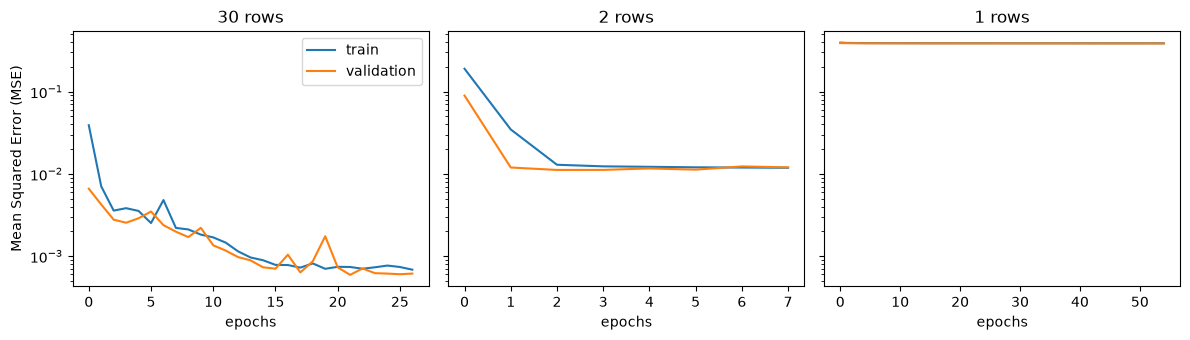

In [53]:
plot_curve(LOOKBACKS, histories)

In [61]:
# Get scores and put them into a pandas dataframe
predictions_df = pd.DataFrame(
    {
        "Predict 0 (KeepSpeed)"
    }
)
# Baseline scores
zero_pred = np.zeros_like(y_test)
last_accel = (X_test[:, -1, 1] - X_test[:, -2, 1]) / DT
score_next_predictions("Predict 0 (Keep Speed)", zero_pred)
score_next_predictions("Repeat last accel (Constant Acceleration)", last_accel)

# Score the models
preds = {}
for k in LOOKBACKS:
    preds[k] = predict(models[k], load_data(X_test[:, -k:], y_test, False))
    score_next_predictions(f"GRU with {k} rows: ", preds[k])

Predict 0 (Keep Speed)                            : MAE: 0.5355 RMSE: 0.7400 R2: -0.0062
Repeat last accel (Constant Acceleration)         : MAE: 0.0745 RMSE: 0.1057 R2: 0.9795
GRU with 30 rows:                                 : MAE: 0.0155 RMSE: 0.0236 R2: 0.9990
GRU with 2 rows:                                  : MAE: 0.0779 RMSE: 0.1060 R2: 0.9794
GRU with 1 rows:                                  : MAE: 0.4669 RMSE: 0.6228 R2: 0.2871
